In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from numpy import array, nan, inf, float32

In [2]:
from data import UncertainDataset, ds_single, ds_pressure

In [3]:
from dataclasses import dataclass

@dataclass
class CompressionRatios:
    percentile: list[float]
    linquant: list[float]
    bitround: list[float]

In [4]:
def parse_single(path: Path):
    with Path(path).open() as f:
        for l in f.readlines():
            var, rest = l.split(": ", 1)
            # FIXME
            try:
                info = eval(rest)
            except SyntaxError:
                return

            yield var, info

In [5]:
def parse_pressure(path: Path):
    with Path(path).open() as f:
        ls = iter(f.readlines())
        
        l = None
        
        while True:
            if l is None:
                try:
                    l = next(ls)
                except:
                    break
        
            var, rest = l.split(":", 1)
        
            while True:
                try:
                    l = next(ls)
                except:
                    l = None
                    break
        
                if len(l.strip()) == 0:
                    continue
        
                if not l.startswith(" - "):
                    break
        
                level, rest = l[len(" - "):].split(": ", 1)
                # FIXME
                try:
                    info = eval(rest)
                except SyntaxError:
                    return
        
                yield var, level, info

In [6]:
single_compression_ratio = dict(parse_single("compression-ratio-single.txt"))

In [7]:
pressure_compression_ratio = dict()
for var, level, info in parse_pressure("compression-ratio-pressure.txt"):
    if var not in pressure_compression_ratio:
        pressure_compression_ratio[var] = dict()
    pressure_compression_ratio[var][level] = info

In [8]:
from matplotlib import pyplot as plt

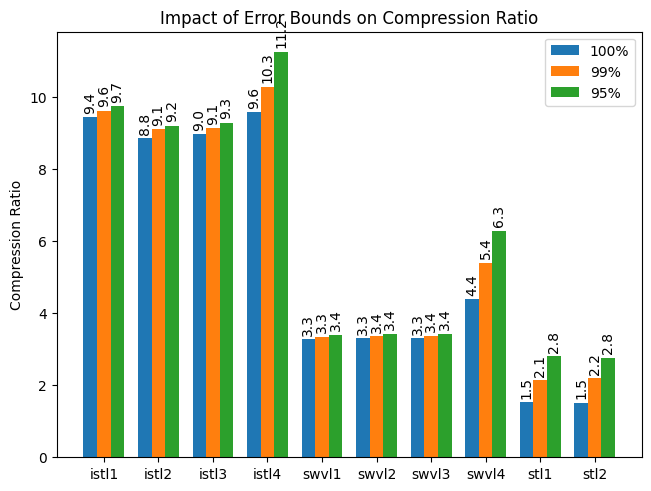

In [9]:
percentiles = ["100%", "99%", "95%"]
variables = list(single_compression_ratio)[:10]

x = np.arange(len(variables))
width = 0.25

fig, ax = plt.subplots(layout="constrained")

multiplier = 0
for i, p in enumerate(percentiles):
    offset = width * multiplier
    rects = ax.bar(x + offset, [single_compression_ratio[var].linquant[i] for var in variables], width, label=p)
    ax.bar_label(rects, fmt="%.1f", padding=3, rotation="vertical")
    multiplier += 1

ax.set_ylabel("Compression Ratio")
ax.set_title("Impact of Error Bounds on Compression Ratio")
ax.set_xticks(x + width, variables)
ax.legend()

plt.show()

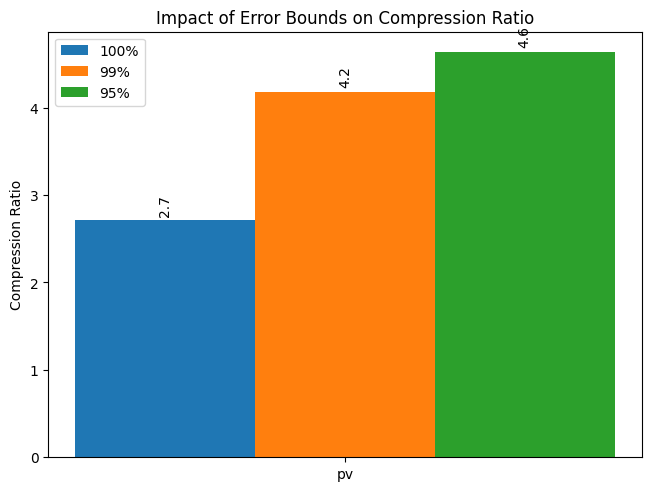

In [10]:
percentiles = ["100%", "99%", "95%"]
variables = list(pressure_compression_ratio)[:10]

x = np.arange(len(variables))
width = 0.25

fig, ax = plt.subplots(layout="constrained")

multiplier = 0
for i, p in enumerate(percentiles):
    offset = width * multiplier
    rects = ax.bar(x + offset, [pressure_compression_ratio[var]["50.0 hPa"].linquant[i] for var in variables], width, label=p)
    ax.bar_label(rects, fmt="%.1f", padding=3, rotation="vertical")
    multiplier += 1

ax.set_ylabel("Compression Ratio")
ax.set_title("Impact of Error Bounds on Compression Ratio")
ax.set_xticks(x + width, variables)
ax.legend()

plt.show()